# Задание 1

Новый счёт получает автоматический номер, начиная с ACC-1000.
Суммы округляются до копеек. Неверные суммы вызывают исключение,
а отклонённое снятие записывается в историю со статусом `fail`.

In [1]:
import csv
import json
import math
import re
from datetime import datetime, timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd


class BankAccount:
    account_type = 'checking'
    allowed_operations = {'deposit', 'withdraw'}
    _next_number = 1000
    _used_numbers = set()
    _next_transfer = 1

    def __init__(self, owner, balance=0, account_number=None):
        word = r'(?:[А-ЯЁ][а-яё]+|[A-Z][a-z]+)'
        if not isinstance(owner, str) or not re.fullmatch(
            word + ' ' + word, owner
        ):
            raise ValueError('Имя владельца: Имя Фамилия, с заглавных букв')
        balance = self._amount(balance, allow_zero=True)

        # Номер вручную нужен только для восстановления счёта из файла.
        if account_number is None:
            while f'ACC-{BankAccount._next_number}' in self._used_numbers:
                BankAccount._next_number += 1
            account_number = f'ACC-{BankAccount._next_number}'
            BankAccount._next_number += 1
        elif not isinstance(account_number, str) or not re.fullmatch(
            r'ACC-\d{4,}', account_number
        ):
            raise ValueError('Неверный номер счёта')
        if account_number in self._used_numbers:
            raise ValueError('Такой номер счёта уже существует')

        self.owner = owner
        self._number = account_number
        self._balance = balance
        self._history = []
        BankAccount._used_numbers.add(account_number)

    @staticmethod
    def _amount(value, allow_zero=False):
        """Проверяет число и округляет денежную сумму до копеек."""
        if isinstance(value, bool):
            raise ValueError('Сумма должна быть числом, а не bool')
        try:
            number = float(value)
        except (TypeError, ValueError, OverflowError):
            raise ValueError('Сумма должна быть числом') from None
        if not math.isfinite(number) or number < 0:
            raise ValueError('Сумма должна быть конечной и неотрицательной')
        number = round(number, 2)
        if not allow_zero and number <= 0:
            raise ValueError('Сумма должна быть положительной')
        return number

    @property
    def account_number(self):
        return self._number

    @property
    def balance(self):
        return self._balance

    @property
    def history(self):
        columns = [
            'operation', 'amount', 'date', 'balance_after', 'status',
            'reason', 'transfer_id', 'counterparty',
        ]
        return pd.DataFrame(self._history, columns=columns)

    def __str__(self):
        return (
            f'{self.account_number}, {self.account_type}, {self.owner}, '
            f'баланс: {self.balance:.2f}'
        )

    def _withdrawal_error(self, amount):
        if amount > self.balance:
            return 'Недостаточно средств'
        return ''

    def _record(self, operation, amount, date, status, reason='',
                transfer_id=None, counterparty=None):
        self._history.append({
            'operation': operation,
            'amount': amount,
            'date': date,
            'balance_after': self.balance,
            'status': status,
            'reason': reason,
            'transfer_id': transfer_id,
            'counterparty': counterparty,
        })

    def _apply(self, operation, amount, date=None, transfer_id=None,
               counterparty=None):
        amount = self._amount(amount)
        if operation not in self.allowed_operations:
            raise ValueError('Операция не разрешена для этого типа счёта')
        if date is None:
            date = datetime.now()
        if not isinstance(date, datetime):
            raise ValueError('Дата должна быть объектом datetime')
        reason = ''
        if operation == 'withdraw':
            reason = self._withdrawal_error(amount)
        change = -amount if operation == 'withdraw' else amount
        if not reason:
            new_balance = self._amount(self.balance + change, True)
            self._balance = new_balance
        status = 'fail' if reason else 'success'
        self._record(
            operation, amount, date, status, reason,
            transfer_id, counterparty,
        )
        return status == 'success'

    def deposit(self, amount, date=None):
        return self._apply('deposit', amount, date)

    def withdraw(self, amount, date=None):
        return self._apply('withdraw', amount, date)

    def large_operations(self, threshold, n):
        """Последние N успешных операций с суммой не меньше порога."""
        threshold = self._amount(threshold, allow_zero=True)
        if isinstance(n, bool) or not isinstance(n, int) or n <= 0:
            raise ValueError('N должно быть положительным целым числом')
        history = self.history
        selected = history[
            history['status'].eq('success')
            & history['amount'].ge(threshold)
        ]
        # При одинаковом времени более поздняя запись идёт первой.
        selected = selected.iloc[::-1]
        return selected.sort_values(
            'date', ascending=False, kind='stable'
        ).head(n).reset_index(drop=True)

    def transfer_to(self, recipient, amount):
        """Связанные записи имеют общий номер перевода и одно время."""
        if not isinstance(recipient, BankAccount) or recipient is self:
            raise ValueError('Получатель должен быть другим счётом')
        amount = self._amount(amount)
        reason = self._withdrawal_error(amount)
        # Проверяем обе стороны до изменения любого баланса.
        if not reason:
            self._amount(recipient.balance + amount, allow_zero=True)
        transfer_id = f'TR-{BankAccount._next_transfer}'
        BankAccount._next_transfer += 1
        date = datetime.now()
        success = self._apply(
            'withdraw', amount, date, transfer_id,
            recipient.account_number,
        )
        if success:
            recipient._apply(
                'deposit', amount, date, transfer_id, self.account_number,
            )
        else:
            recipient._record(
                'deposit', amount, date, 'fail',
                'Перевод отклонён отправителем: ' + reason,
                transfer_id, self.account_number,
            )
        return success

In [2]:
account = BankAccount('Олег Алексеенко', 1000)
start = datetime(2026, 10, 18, 10, 0)
account.deposit(500, start)
account.withdraw(300, start + timedelta(minutes=1))
account.deposit(200, start + timedelta(minutes=2))
account.withdraw(2000, start + timedelta(minutes=3))
account.withdraw(400, start + timedelta(minutes=4))

print(account)
display(account.history)

ACC-1000, checking, Олег Алексеенко, баланс: 1000.00


,operation,amount,date,balance_after,status,reason,transfer_id,counterparty
0,deposit,500.0,2026-10-18 10:00:00,1500.0,success,,None,None
1,withdraw,300.0,2026-10-18 10:01:00,1200.0,success,,None,None
2,deposit,200.0,2026-10-18 10:02:00,1400.0,success,,None,None
3,withdraw,2000.0,2026-10-18 10:03:00,1400.0,fail,Недостаточно средств,None,None
4,withdraw,400.0,2026-10-18 10:04:00,1000.0,success,,None,None


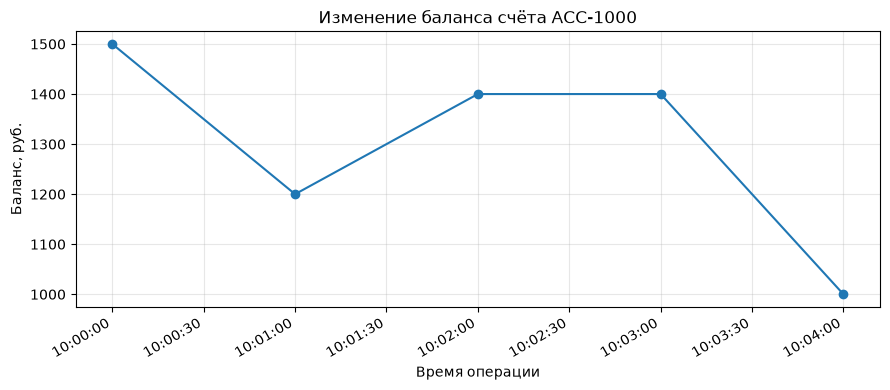

In [3]:
history = account.history
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(history['date'], history['balance_after'], marker='o')
ax.set_title('Изменение баланса счёта ' + account.account_number)
ax.set_xlabel('Время операции')
ax.set_ylabel('Баланс, руб.')
ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

# Задание 2

Расчётный счёт использует общие правила. Сберегательный дополнительно
начисляет проценты и проверяет ограничение на снятие.
При одинаковом времени последней считается запись, добавленная позже.

In [4]:
class CheckingAccount(BankAccount):
    account_type = 'checking'


class SavingsAccount(BankAccount):
    account_type = 'savings'
    allowed_operations = {'deposit', 'withdraw', 'interest'}

    def _withdrawal_error(self, amount):
        reason = super()._withdrawal_error(amount)
        if reason:
            return reason
        if amount > self.balance / 2:
            return 'Нельзя снять больше 50% текущего баланса'
        return ''

    def add_interest(self, rate):
        rate = self._amount(rate)
        amount = self._amount(self.balance * rate / 100, allow_zero=True)
        # Если проценты округлились до нуля, операции не происходит.
        if amount == 0:
            return False
        return self._apply('interest', amount)

In [5]:
checking = CheckingAccount('Олег Алексеенко', 2000)
savings = SavingsAccount('Анна Петрова', 1000)
checking.deposit(500)
checking.withdraw(1700)
savings.deposit(1000)
savings.add_interest(7)
print('Снятие 1200:', savings.withdraw(1200))
print('Снятие ровно 50%:', savings.withdraw(1070))

print(checking)
print(savings)
display(checking.history)
display(savings.history)
display(savings.large_operations(threshold=500, n=2))

Снятие 1200: False
Снятие ровно 50%: True
ACC-1001, checking, Олег Алексеенко, баланс: 800.00
ACC-1002, savings, Анна Петрова, баланс: 1070.00


,operation,amount,date,balance_after,status,reason,transfer_id,counterparty
0,deposit,500.0,2026-10-18 13:49:56.161577,2500.0,success,,None,None
1,withdraw,1700.0,2026-10-18 13:49:56.161577,800.0,success,,None,None


,operation,amount,date,balance_after,status,reason,transfer_id,counterparty
0,deposit,1000.0,2026-10-18 13:49:56.161577,2000.0,success,,None,None
1,interest,140.0,2026-10-18 13:49:56.161577,2140.0,success,,None,None
2,withdraw,1200.0,2026-10-18 13:49:56.161577,2140.0,fail,Нельзя снять больше 50% текущего баланса,None,None
3,withdraw,1070.0,2026-10-18 13:49:56.161577,1070.0,success,,None,None


,operation,amount,date,balance_after,status,reason,transfer_id,counterparty
0,withdraw,1070.0,2026-10-18 13:49:56.161577,1070.0,success,,None,None
1,deposit,1000.0,2026-10-18 13:49:56.161577,2000.0,success,,None,None


In [6]:
try:
    CheckingAccount('олег Алексеенко')
except ValueError as error:
    print('Ошибка имени:', error)

for amount in (0, -100, 'текст'):
    try:
        checking.deposit(amount)
    except ValueError as error:
        print(f'Сумма {amount!r}: {error}')

try:
    CheckingAccount('Олег Алексеенко', -100)
except ValueError as error:
    print('Ошибка начального баланса:', error)

Ошибка имени: Имя владельца: Имя Фамилия, с заглавных букв
Сумма 0: Сумма должна быть положительной
Сумма -100: Сумма должна быть конечной и неотрицательной
Сумма 'текст': Сумма должна быть числом
Ошибка начального баланса: Сумма должна быть конечной и неотрицательной


## Переводы

Метод `transfer_to` использует те же правила снятия. Записи обеих сторон
связаны через `transfer_id`, в `counterparty` указан второй счёт.
При отказе балансы обеих сторон остаются прежними.

In [7]:
total_before = checking.balance + savings.balance
print('Перевод 300:', checking.transfer_to(savings, 300))
balances_before = (savings.balance, checking.balance)
print('Перевод 1000 со сберегательного:',
      savings.transfer_to(checking, 1000))

assert (savings.balance, checking.balance) == balances_before
assert round(checking.balance + savings.balance, 2) == total_before
print(checking)
print(savings)
display(checking.history.tail(2))
display(savings.history.tail(2))

Перевод 300: True
Перевод 1000 со сберегательного: False
ACC-1001, checking, Олег Алексеенко, баланс: 500.00
ACC-1002, savings, Анна Петрова, баланс: 1370.00


,operation,amount,date,balance_after,status,reason,transfer_id,counterparty
2,withdraw,300.0,2026-10-18 13:49:56.174270,500.0,success,,TR-1,ACC-1002
3,deposit,1000.0,2026-10-18 13:49:56.175270,500.0,fail,Перевод отклонён отправителем: Нельзя снять бо...,TR-2,ACC-1002


,operation,amount,date,balance_after,status,reason,transfer_id,counterparty
4,deposit,300.0,2026-10-18 13:49:56.174270,1370.0,success,,TR-1,ACC-1001
5,withdraw,1000.0,2026-10-18 13:49:56.175270,1370.0,fail,Нельзя снять больше 50% текущего баланса,TR-2,ACC-1001


# Задание 3

Ошибочные строки и дубли удаляются, баланс пересчитывается.
Начальные остатки в условии не указаны — приняты 1200 и 1500
по первым корректным операциям.

In [8]:
def parse_date(value):
    for date_format in ('%Y-%m-%d %H:%M:%S', '%d/%m/%Y %H:%M'):
        try:
            return datetime.strptime(str(value), date_format)
        except ValueError:
            pass
    raise ValueError('Некорректная дата')


def load_history(account, filename):
    """Восстанавливает историю пустого счёта и возвращает отчёт очистки."""
    if not account.history.empty:
        raise ValueError('Загружать данные нужно в счёт без истории')
    path = Path(filename)
    with path.open(encoding='utf-8-sig', newline='') as file:
        if path.suffix.lower() == '.csv':
            rows = list(csv.DictReader(file))
        elif path.suffix.lower() == '.json':
            rows = json.load(file)
        else:
            raise ValueError('Поддерживаются только CSV и JSON')
    if not isinstance(rows, list):
        raise ValueError('Ожидался список операций')

    report = []
    candidates = []
    seen = set()
    for row_number, row in enumerate(rows, start=1):
        item = {'row': row_number, 'result': 'rejected', 'reason': ''}
        report.append(item)
        try:
            if not isinstance(row, dict):
                raise ValueError('Строка не является записью операции')
            if row.get('account_number') != account.account_number:
                item.update(result='skipped', reason='Другой счёт')
                continue
            if row.get('account_type') != account.account_type:
                raise ValueError('Неверный тип счёта')
            operation = row.get('operation')
            if operation not in account.allowed_operations:
                raise ValueError(f'Недопустимая операция: {operation!r}')
            amount = account._amount(row.get('amount'))
            date = parse_date(row.get('date'))
            status = row.get('status')
            if status not in ('success', 'fail'):
                raise ValueError(f'Некорректный статус: {status!r}')
            account._amount(row.get('balance_after'), allow_zero=True)
            key = json.dumps(row, sort_keys=True, ensure_ascii=False)
            if key in seen:
                raise ValueError('Полный дубль записи')
            seen.add(key)
            candidates.append((date, row_number, operation, amount, status))
        except ValueError as error:
            item['reason'] = str(error)

    # При одинаковом времени сохраняется порядок строк исходного файла.
    for date, row_number, operation, amount, status in sorted(candidates):
        item = report[row_number - 1]
        reason = ''
        if status == 'success' and operation == 'withdraw':
            reason = account._withdrawal_error(amount)
        if reason:
            item['reason'] = 'Успех в файле противоречит правилам: ' + reason
            continue
        if status == 'fail':
            account._record(
                operation, amount, date, 'fail', 'Отказ из исходного файла',
            )
        else:
            try:
                account._apply(operation, amount, date)
            except ValueError as error:
                item['reason'] = str(error)
                continue
        item.update(result='accepted', reason='')
    return pd.DataFrame(report)

In [9]:
loaded_checking = CheckingAccount(
    'Олег Алексеенко', 1200, account_number='ACC-100001',
)
loaded_savings = SavingsAccount(
    'Анна Петрова', 1500, account_number='ACC-100002',
)
checking_report = load_history(loaded_checking, 'transactions_dirty.csv')
savings_report = load_history(loaded_savings, 'transactions_dirty.json')

print(loaded_checking)
display(loaded_checking.history.head(3))
display(loaded_checking.history.tail(3))
print(loaded_savings)
display(loaded_savings.history.head(3))
display(loaded_savings.history.tail(3))

ACC-100001, checking, Олег Алексеенко, баланс: 4864.00


,operation,amount,date,balance_after,status,reason,transfer_id,counterparty
0,deposit,921.0,2025-09-27 22:17:26,2121.0,success,,None,None
1,deposit,607.0,2025-09-27 22:17:26,2728.0,success,,None,None
2,deposit,129.0,2025-09-28 22:17:00,2857.0,success,,None,None


,operation,amount,date,balance_after,status,reason,transfer_id,counterparty
14,deposit,701.0,2025-10-16 22:17:26,5037.0,success,,None,None
15,withdraw,308.0,2025-10-17 22:17:26,4729.0,success,,None,None
16,deposit,135.0,2025-10-18 22:17:26,4864.0,success,,None,None


ACC-100002, savings, Анна Петрова, баланс: 3991.24


,operation,amount,date,balance_after,status,reason,transfer_id,counterparty
0,deposit,469.0,2025-09-27 22:17:26,1969.0,success,,None,None
1,withdraw,392.0,2025-09-27 22:17:26,1577.0,success,,None,None
2,deposit,317.0,2025-09-28 22:17:26,1894.0,success,,None,None


,operation,amount,date,balance_after,status,reason,transfer_id,counterparty
15,withdraw,286.00,2025-10-17 22:17:26,3971.11,success,,None,None
16,interest,302.13,2025-10-20 22:17:26,4273.24,success,,None,None
17,withdraw,282.00,2025-10-23 22:17:26,3991.24,success,,None,None


## Отчёт очистки

`accepted` — принято, `rejected` — отклонено, `skipped` — другой счёт.
`row` — номер записи в файле, начиная с 1 (заголовок CSV не считается).
Для отклонённой строки показана первая найденная причина.

In [10]:
for name, report in (
    ('Расчётный счёт, CSV', checking_report),
    ('Сберегательный счёт, JSON', savings_report),
):
    print(name)
    display(report['result'].value_counts().rename('rows').to_frame())
    display(report[report['result'].eq('rejected')].reset_index(drop=True))

Расчётный счёт, CSV


,rows
result,
skipped,79
accepted,17
rejected,9


,row,result,reason
0,6,rejected,Сумма должна быть числом
1,9,rejected,Недопустимая операция: ''
2,11,rejected,Недопустимая операция: 'interest'
3,14,rejected,Некорректная дата
4,16,rejected,Недопустимая операция: 'diposit'
5,17,rejected,Недопустимая операция: 'interest'
6,18,rejected,Некорректная дата
7,25,rejected,Некорректный статус: 'succes'
8,105,rejected,Полный дубль записи


Сберегательный счёт, JSON


,rows
result,
skipped,78
accepted,18
rejected,9


,row,result,reason
0,29,rejected,Некорректная дата
1,30,rejected,Сумма должна быть числом
2,34,rejected,Сумма должна быть конечной и неотрицательной
3,38,rejected,Недопустимая операция: 'diposit'
4,45,rejected,Сумма должна быть конечной и неотрицательной
5,47,rejected,Некорректный статус: 'succes'
6,49,rejected,Недопустимая операция: 'wdraw'
7,101,rejected,Полный дубль записи
8,104,rejected,Некорректный статус: 'succes'


In [11]:
assert loaded_checking.balance == 4864.00
assert loaded_savings.balance == 3991.24
assert len(loaded_checking.history) == 17
assert len(loaded_savings.history) == 18

for restored, opening_balance in (
    (loaded_checking, 1200), (loaded_savings, 1500),
):
    history = restored.history
    successful = history[history['status'].eq('success')]
    incoming = successful.loc[
        successful['operation'].isin(['deposit', 'interest']), 'amount',
    ].sum()
    outgoing = successful.loc[
        successful['operation'].eq('withdraw'), 'amount',
    ].sum()
    assert round(opening_balance + incoming - outgoing, 2) == restored.balance
    assert history['date'].is_monotonic_increasing

print('Проверки истории и балансов пройдены')

Проверки истории и балансов пройдены
